In [56]:
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix, roc_curve, roc_auc_score,precision_score

In [2]:
claimants_data = pd.read_csv("Claimants.csv")

## Data understanding

In [3]:
claimants_data.shape

(1340, 7)

In [4]:
claimants_data.describe()

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
count,1340.000000,1340.000000,1328.000000,1299.000000,1292.000000,1151.000000,1340.000000
mean,11202.001493,0.488806,0.558735,0.907621,0.017028,28.414422,3.806307
std,9512.750796,0.500061,0.496725,0.289671,0.129425,20.304451,10.636903
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4177.000000,0.000000,0.000000,1.000000,0.000000,9.000000,0.400000
50%,8756.500000,0.000000,1.000000,1.000000,0.000000,30.000000,1.069500
75%,15702.500000,1.000000,1.000000,1.000000,0.000000,43.000000,3.781500
max,34153.000000,1.000000,1.000000,1.000000,1.000000,95.000000,173.604000


In [5]:
claimants_data

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,5,0,0.0,1.0,0.0,50.0,34.940
1,3,1,1.0,0.0,0.0,18.0,0.891
2,66,1,0.0,1.0,0.0,5.0,0.330
3,70,0,0.0,1.0,1.0,31.0,0.037
4,96,1,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...,...,...
1335,34100,1,0.0,1.0,0.0,NaN,0.576
1336,34110,0,1.0,1.0,0.0,46.0,3.705
1337,34113,1,1.0,1.0,0.0,39.0,0.099
1338,34145,0,1.0,0.0,0.0,8.0,3.177


In [6]:
claimants_data.isna().sum()

CASENUM       0
ATTORNEY      0
CLMSEX       12
CLMINSUR     41
SEATBELT     48
CLMAGE      189
LOSS          0
dtype: int64

In [7]:
claimants_data.dtypes

CASENUM       int64
ATTORNEY      int64
CLMSEX      float64
CLMINSUR    float64
SEATBELT    float64
CLMAGE      float64
LOSS        float64
dtype: object

## Data Preparation

In [8]:
claimants_data.dropna(axis=0,inplace=True)

In [9]:
claimants_data.shape

(1096, 7)

In [10]:
claimants_data.isna().sum()

CASENUM     0
ATTORNEY    0
CLMSEX      0
CLMINSUR    0
SEATBELT    0
CLMAGE      0
LOSS        0
dtype: int64

## Separate your inputs

In [11]:
X = claimants_data.drop(labels = ["CASENUM","ATTORNEY"], axis=1)
X

,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,0.0,1.0,0.0,50.0,34.940
1,1.0,0.0,0.0,18.0,0.891
2,0.0,1.0,0.0,5.0,0.330
3,0.0,1.0,1.0,31.0,0.037
4,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...
1334,1.0,1.0,0.0,16.0,0.060
1336,1.0,1.0,0.0,46.0,3.705
1337,1.0,1.0,0.0,39.0,0.099
1338,1.0,0.0,0.0,8.0,3.177


In [12]:
y= claimants_data["ATTORNEY"]
y

0       0
1       1
2       1
3       0
4       1
       ..
1334    1
1336    0
1337    1
1338    0
1339    1
Name: ATTORNEY, Length: 1096, dtype: int64

## Model Building

In [13]:
from sklearn.model_selection import train_test_split

In [33]:
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size = 0.20, shuffle=True , random_state=34)

In [34]:
X_train

,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
478,0.0,1.0,1.0,10.0,1.318
387,1.0,1.0,0.0,55.0,0.604
47,0.0,1.0,0.0,1.0,0.000
220,1.0,1.0,1.0,7.0,0.983
152,1.0,1.0,0.0,6.0,0.075
...,...,...,...,...,...
731,0.0,1.0,0.0,30.0,4.014
817,0.0,1.0,0.0,48.0,0.390
557,0.0,1.0,0.0,30.0,0.565
386,1.0,1.0,0.0,35.0,0.860


In [35]:
logistc_model= LogisticRegression()

## Model Training

In [36]:
logistc_model.fit(X_train,y_train)

LogisticRegression()

In [37]:
X_train

,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
478,0.0,1.0,1.0,10.0,1.318
387,1.0,1.0,0.0,55.0,0.604
47,0.0,1.0,0.0,1.0,0.000
220,1.0,1.0,1.0,7.0,0.983
152,1.0,1.0,0.0,6.0,0.075
...,...,...,...,...,...
731,0.0,1.0,0.0,30.0,4.014
817,0.0,1.0,0.0,48.0,0.390
557,0.0,1.0,0.0,30.0,0.565
386,1.0,1.0,0.0,35.0,0.860


## Model Testing
## Predicting with Training data

In [38]:
y_train_pred = logistc_model.predict(X_train)
y_train_pred 

array([0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0,
       0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1,
       0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1,
       1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0,
       1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1,
       0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0,
       1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1,
       1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1,
       1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0,
       1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1,
       1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1,
       1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1,

## Predicting with Unseen data (X_test)

In [39]:
X_test

,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
627,1.0,1.0,0.0,40.0,6.337
1125,1.0,1.0,0.0,37.0,4.609
1124,1.0,1.0,0.0,46.0,0.730
1025,1.0,1.0,0.0,38.0,3.406
481,1.0,1.0,0.0,70.0,0.566
...,...,...,...,...,...
658,0.0,1.0,0.0,14.0,4.479
1257,0.0,1.0,0.0,7.0,0.453
1015,1.0,0.0,0.0,69.0,3.110
1114,1.0,1.0,0.0,0.0,7.169


In [40]:
y_test_pred = logistc_model.predict(X_test)
y_test_pred

array([0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1,
       1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0,
       0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1,
       1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0,
       0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1,
       1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1,
       1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0])

In [22]:
# claimants_data["Predicted_Output"] = logistc_model.predict(X_train)
# claimants_data

## Model Evaluation

## 8.1 Training Data Evaluaiton Metrics

In [55]:
confusion_matrix(y_train, y_train_pred)

array([[297, 156],
       [ 99, 324]])

In [46]:
print (classification_report(y_train, y_train_pred))

              precision    recall  f1-score   support

           0       0.75      0.66      0.70       453
           1       0.68      0.77      0.72       423

    accuracy                           0.71       876
   macro avg       0.71      0.71      0.71       876
weighted avg       0.71      0.71      0.71       876



In [53]:
accuracy_score(y_train,y_train_pred)

0.708904109589041

## 8.2 Test Data Evaluation Metrics

In [51]:
confusion_matrix(y_test, y_test_pred)

array([[78, 47],
       [23, 72]])

In [52]:
print (classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.77      0.62      0.69       125
           1       0.61      0.76      0.67        95

    accuracy                           0.68       220
   macro avg       0.69      0.69      0.68       220
weighted avg       0.70      0.68      0.68       220



In [54]:
accuracy_score(y_test,y_test_pred)

0.6818181818181818

In [57]:
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix, roc_curve, roc_auc_score,precision_score

In [79]:
# fpr, tpr, thresholds = roc_curve(y_train, logistc_model.predict_proba(X_train)[:,1])
fpr, tpr, thresholds = roc_curve(y_train, logistc_model.predict_proba(X_train)[:,1])

auc = roc_curve(y_train, y_train_pred)
auc

from matplotlib import pyplot as plt
plt.plot(fpr, tpr ,color='red', label='logit model (area=%0.8f)'%auc)

TypeError: only length-1 arrays can be converted to Python scalars

In [62]:
fpr

array([0.        , 0.        , 0.        , 0.00220751, 0.00220751,
       0.00441501, 0.00441501, 0.00883002, 0.00883002, 0.01103753,
       0.01103753, 0.01324503, 0.01324503, 0.01545254, 0.01545254,
       0.01766004, 0.01766004, 0.01986755, 0.01986755, 0.02207506,
       0.02207506, 0.02428256, 0.02428256, 0.02869757, 0.02869757,
       0.03532009, 0.03532009, 0.03532009, 0.03532009, 0.03752759,
       0.03752759, 0.0397351 , 0.0397351 , 0.0419426 , 0.0419426 ,
       0.04415011, 0.04415011, 0.04635762, 0.04856512, 0.04856512,
       0.05077263, 0.05077263, 0.05298013, 0.05298013, 0.05518764,
       0.05518764, 0.05960265, 0.05960265, 0.06181015, 0.06181015,
       0.06401766, 0.06401766, 0.06843267, 0.06843267, 0.07284768,
       0.07284768, 0.07505519, 0.07505519, 0.07726269, 0.07726269,
       0.0794702 , 0.0794702 , 0.08830022, 0.08830022, 0.09050773,
       0.09050773, 0.09271523, 0.09271523, 0.09713024, 0.09713024,
       0.10596026, 0.10596026, 0.10816777, 0.10816777, 0.11258

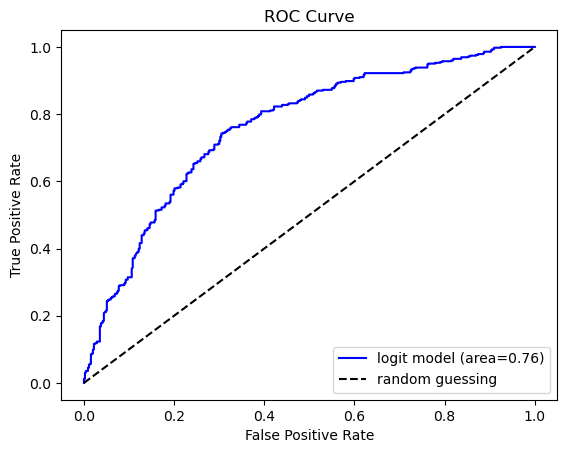

In [94]:
from sklearn.metrics import roc_curve, roc_auc_score
from matplotlib import pyplot as plt
from matplotlib import pyplot as plt

proba = logistc_model.predict_proba(X_train)[:, 1]

fpr, tpr, thresholds = roc_curve(y_train, proba)
auc = roc_auc_score(y_train, proba)          # a single number

plt.plot(fpr, tpr, color='blue', label='logit model (area=%0.2f)' % auc)
plt.plot([0, 1], [0, 1], 'k--', label='random guessing')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

## ROC curve for Training data

In [95]:
from sklearn.metrics import roc_curve,roc_auc_score
from matplotlib import pyplot as plt


In [84]:
proba = logistc_model.predict_proba(X_train)
proba

array([[7.06877042e-01, 2.93122958e-01],
       [2.64655817e-01, 7.35344183e-01],
       [4.04452938e-01, 5.95547062e-01],
       ...,
       [3.96695534e-01, 6.03304466e-01],
       [3.18651616e-01, 6.81348384e-01],
       [1.00000000e+00, 1.82875319e-10]])

In [98]:
proba = logistc_model.predict_proba(X_train)[:,1]



In [102]:
# Generate the ROC curve
fpr, tpr, thresholds = roc_curve(y_train, y_train_pred)

In [113]:
# Generate the Random guessing line
auc = roc_auc_score(y_train, y_train_pred)

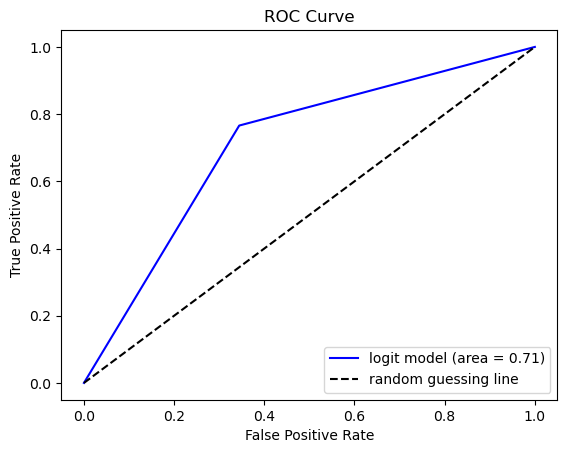

In [142]:
# plt.plot(fpr, tpr, colr='red', label='logit model ( area=%0.2f)'%auc)
plt.plot(fpr, tpr, color='blue', label='logit model (area = %0.2f)' %auc)
# plt.plot(fpr, tpr, color='blue', label=f'logit model (area = {auc:.2f})')
plt.plot([0,1], [0,1],'k--',label='random guessing line')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

In [50]:
accuracy_score(y_test, y_tes)

0.6818181818181818

In [25]:
y

0       0
1       1
2       1
3       0
4       1
       ..
1334    1
1336    0
1337    1
1338    0
1339    1
Name: ATTORNEY, Length: 1096, dtype: int64

## Model Deployment

In [26]:
from pickle import dump

In [27]:
dump(logistc_model,open("claimans.pkl", "wb"))